# Pronóstico de ventas por SKU
## Parte 5: pronóstico junio-agosto 2025

Cada SKU usa el modelo elegido en el notebook 03 y confirmado en el test del notebook 04. Se entrena con los 53 meses, de enero 2021 a mayo 2025.

| SKU | Modelo |
|---|---|
| A | Seasonal Naive |
| B | Media M3 |
| C | Media |
| D | Media |
| E | Holt-Winters |

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from funciones import *

In [2]:
ventas = cargar_ventas()
skus = ["A", "B", "C", "D", "E"]
meses = ["2025-06", "2025-07", "2025-08"]

In [3]:
elegido = {"A": seasonal_naive, "B": media_movil_3, "C": media, "D": media, "E": holt_winters}
nombre = {"A": "Seasonal Naive", "B": "Media M3", "C": "Media", "D": "Media", "E": "Holt-Winters"}

## Pronóstico

In [4]:
pronostico = pd.DataFrame({s: elegido[s](ventas[s], 3) for s in skus}, index=meses).T
pronostico["Modelo"] = pd.Series(nombre)
pronostico.round(1)

,2025-06,2025-07,2025-08,Modelo
A,25.0,50.0,55.0,Seasonal Naive
B,52.0,52.0,52.0,Media M3
C,23.2,23.2,23.2,Media
D,77.6,77.6,77.6,Media
E,135.0,170.9,177.5,Holt-Winters


- A: repite junio-agosto 2024 (25, 50 y 55). En el test A vendió más que el año anterior, así que puede quedar corto.
- B: 52 por mes, el promedio de marzo a mayo 2025.
- C: 23 por mes, el promedio de toda la historia.
- D: 78 por mes. Es alto comparado con 2025, que promedió 49.
- E: 135, 171 y 178. Holt-Winters espera la subida del segundo semestre que hubo en 2023 y 2024 (junio-agosto 2024: 141, 169 y 187). Pero E bajó en 2025 hasta 116 en mayo, y en el test Holt-Winters se pasó en marzo, abril y mayo. Si la caída sigue, estos valores quedan altos.

## Rango del pronóstico

Para cada SKU y horizonte junto los errores que tuvo el modelo elegido en todos los cortes, de diciembre 2022 a febrero 2025 (27 por horizonte). Con esos errores armo un rango:
- Máximo: el pronóstico menos el error del percentil 10. En 9 de cada 10 casos pasados la venta real quedó por debajo.
- Mínimo: el pronóstico menos el error del percentil 90. En 9 de cada 10 casos la venta real quedó por encima.

Entre los dos queda el 80% de los casos pasados.

In [5]:
cortes = pd.date_range("2022-12-01", "2025-02-01", freq="MS")

errores = []
for s in skus:
    errores.append(walk_forward(ventas, [s], {nombre[s]: elegido[s]}, cortes))

errores = pd.concat(errores)
p10 = errores.groupby(["SKU", "Horizonte"])["Error"].quantile(0.1)
p90 = errores.groupby(["SKU", "Horizonte"])["Error"].quantile(0.9)

In [6]:
filas = []
for s in skus:
    for i, mes in enumerate(meses):
        filas.append({
            "SKU": s,
            "Mes": mes,
            "Mínimo": pronostico.loc[s, mes] - p90[(s, i + 1)],
            "Pronóstico": pronostico.loc[s, mes],
            "Máximo": pronostico.loc[s, mes] - p10[(s, i + 1)],
        })

rango = pd.DataFrame(filas)
rango.round(0)

,SKU,Mes,Mínimo,Pronóstico,Máximo
0,A,2025-06,8.0,25.0,40.0
1,A,2025-07,33.0,50.0,69.0
2,A,2025-08,38.0,55.0,74.0
3,B,2025-06,29.0,52.0,99.0
4,B,2025-07,33.0,52.0,92.0
5,B,2025-08,31.0,52.0,86.0
6,C,2025-06,14.0,23.0,37.0
7,C,2025-07,14.0,23.0,38.0
8,C,2025-08,14.0,23.0,37.0
9,D,2025-06,26.0,78.0,131.0


- D tiene el rango más ancho: de 23 a 131 unidades por mes. Es el SKU más errático y el pronóstico puntual solo dice poco.
- En B y E el rango se estira más hacia arriba. En el pasado tuvieron saltos hacia arriba que los modelos no anticiparon (B en mayo 2024, E en julio 2023).
- En E el rango se abre con el horizonte: en agosto va de 143 a 271.

## Escenario ajustado para D

El test mostró que la media sobreestima a D: en 2025 vendió 49 por mes y la media pronostica 78. El procedimiento mantiene la media, pero ningún modelo puede decir si la caída de 2025 es permanente. Como alternativa, uso el nivel reciente: la media de los últimos 6 meses.

In [7]:
ajuste_d = media_movil_6(ventas["D"], 3)[0]
print("D oficial (Media):", round(pronostico.loc["D", meses[0]], 1))
print("D ajustado (Media M6):", round(ajuste_d, 1))
print("Promedio 2025:", round(ventas.loc["2025", "D"].mean(), 1))

D oficial (Media): 77.6
D ajustado (Media M6): 54.8
Promedio 2025: 49.0


- La diferencia entre los dos escenarios es de unas 23 unidades por mes.
- Si la caída es permanente (por ejemplo, se perdió un cliente), corresponde el escenario ajustado.
- Si fue falta de stock, las ventas bajas no muestran la demanda real y la media puede estar más cerca.
- La elección depende de la causa y del costo de cada error: sobrestock (capital inmovilizado) o faltante (ventas perdidas).

## Gráfico

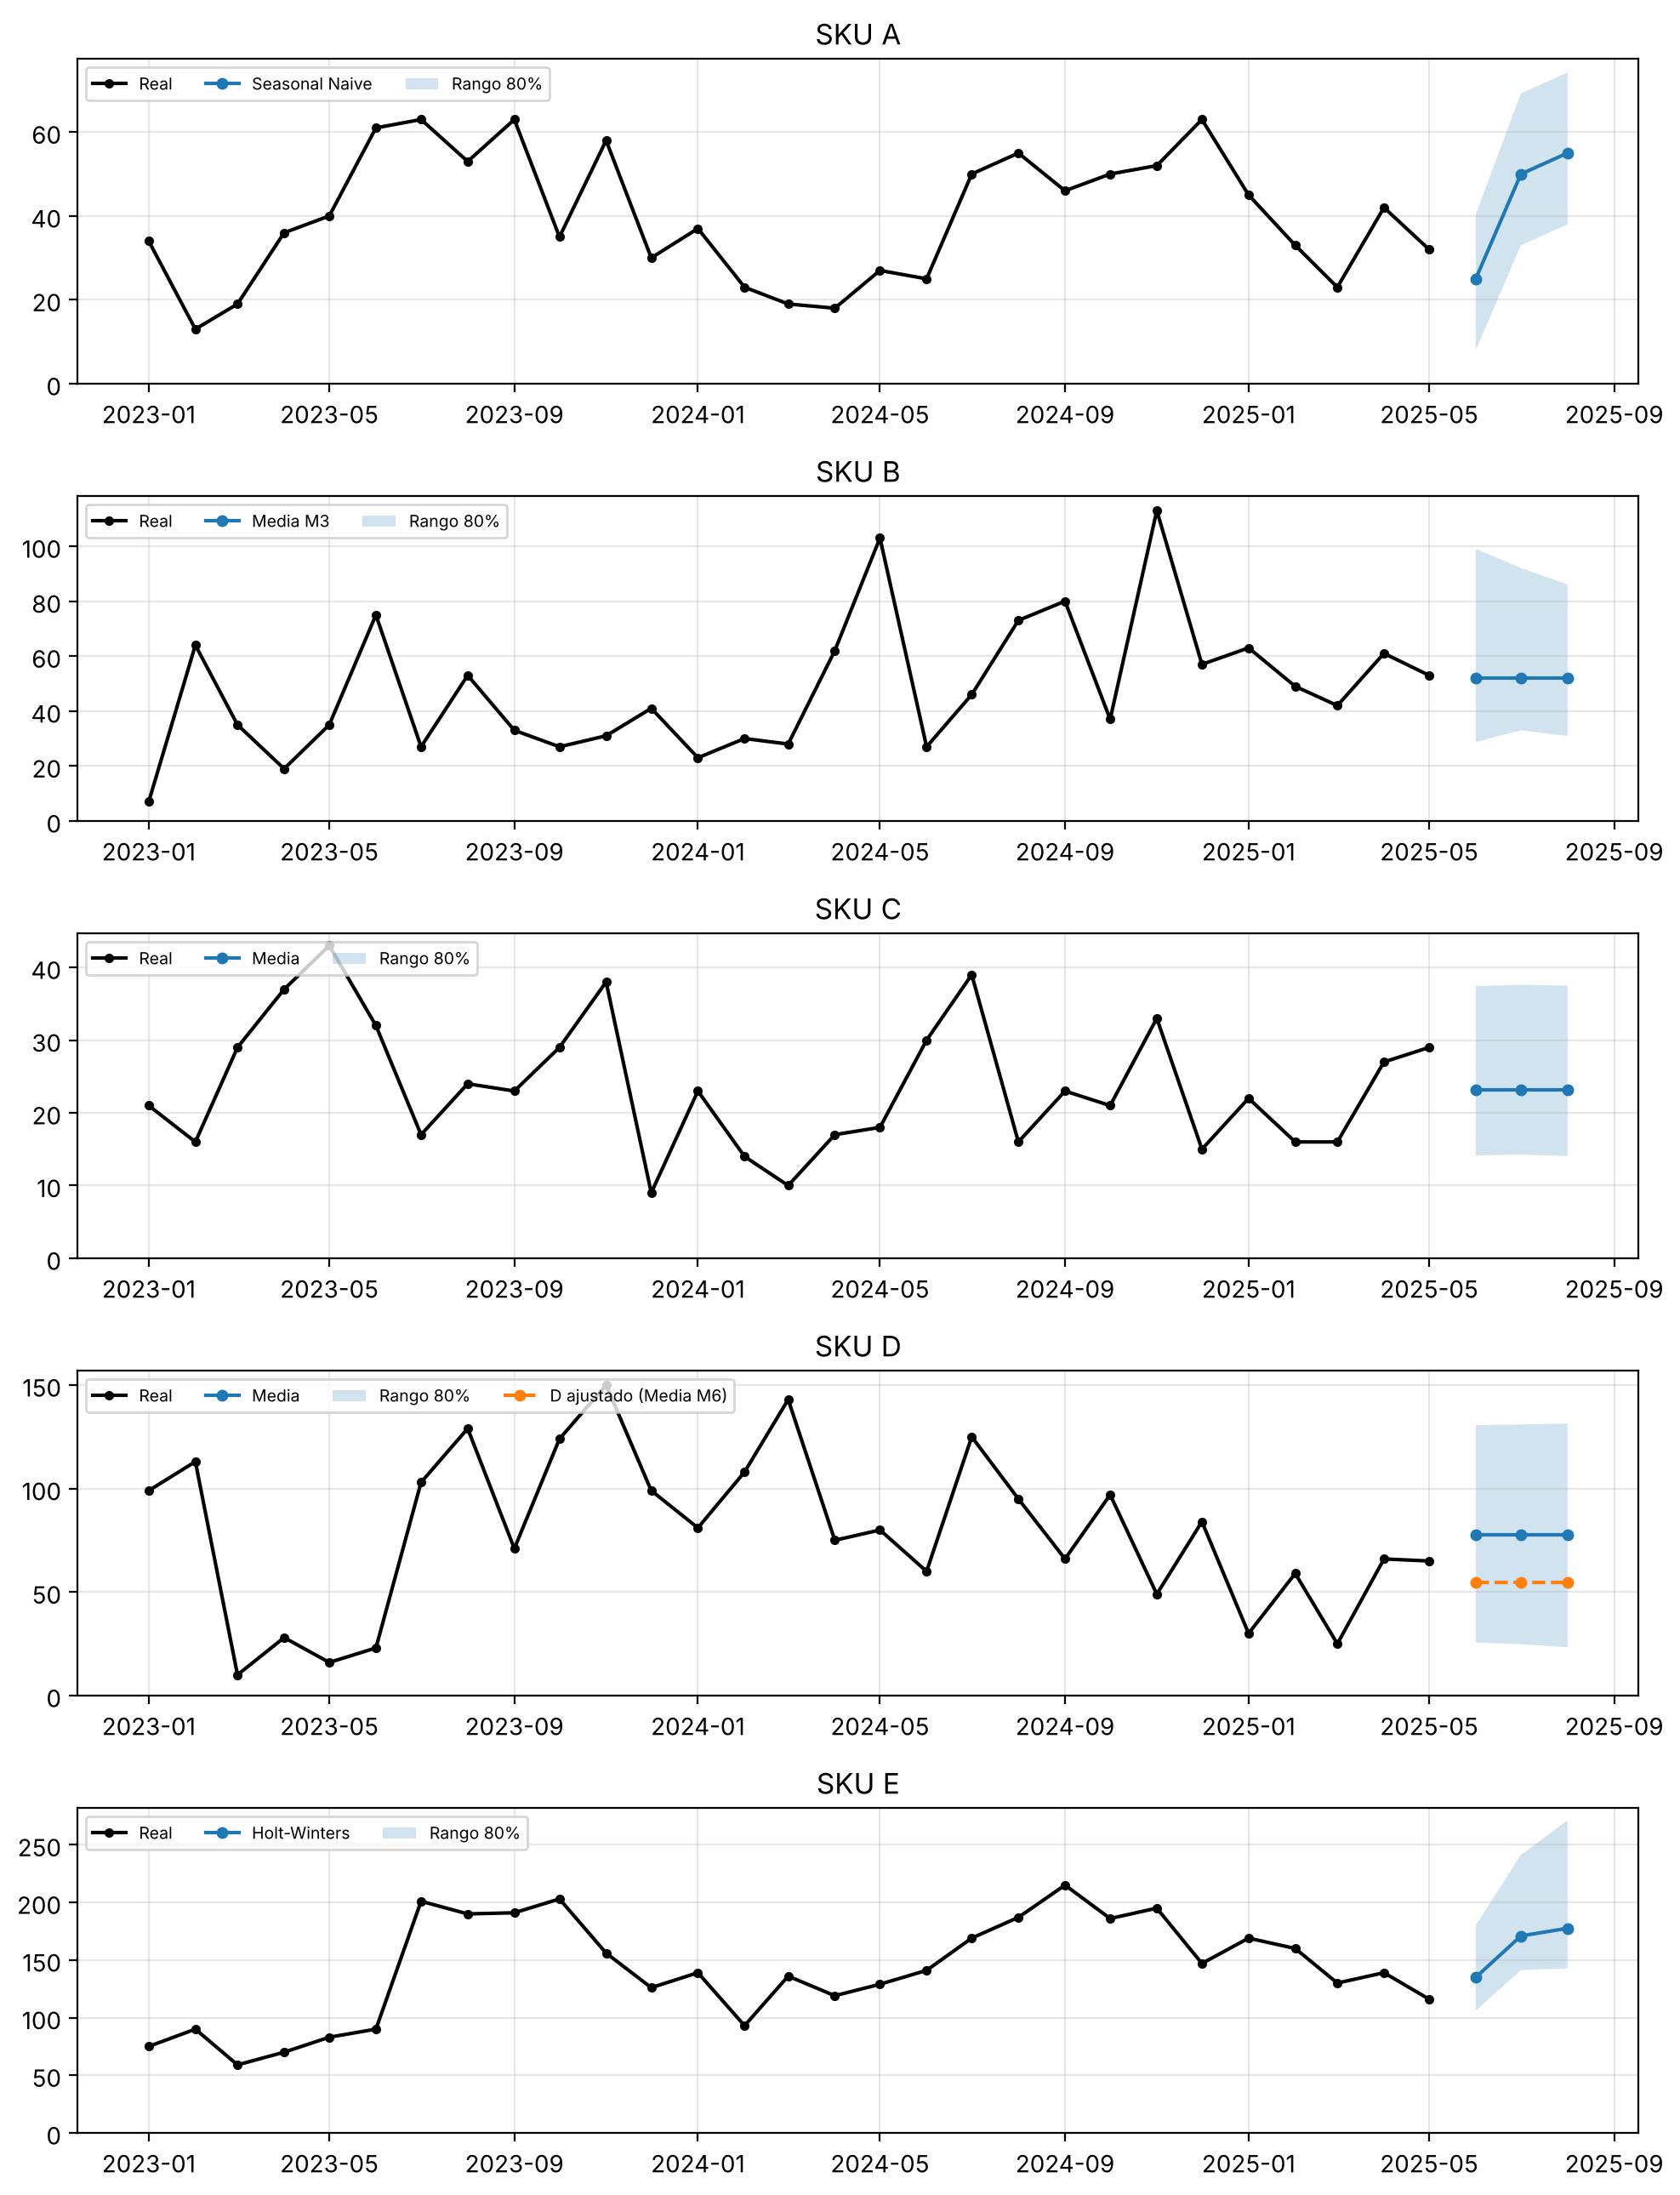

In [8]:
fig, axes = plt.subplots(5, 1, figsize=(10, 13))

for i, s in enumerate(skus):
    r = rango[rango["SKU"] == s]
    fechas = pd.to_datetime(r["Mes"])
    axes[i].plot(ventas.loc["2023-01-01":, s], color="black", marker="o", markersize=3, label="Real")
    axes[i].plot(fechas, r["Pronóstico"], marker="o", markersize=4, label=nombre[s])
    axes[i].fill_between(fechas, r["Mínimo"], r["Máximo"], alpha=0.2, label="Rango 80%")
    if s == "D":
        axes[i].plot(fechas, [ajuste_d] * 3, linestyle="--", marker="o", markersize=4, label="D ajustado (Media M6)")
    axes[i].set_title(f"SKU {s}")
    axes[i].set_ylim(bottom=0)
    axes[i].grid(alpha=0.3)
    axes[i].legend(fontsize=7, ncol=4, loc="upper left")

plt.tight_layout()
plt.show()

## Conclusiones

Pronóstico junio-agosto 2025 (unidades por mes):

| SKU | Modelo | Junio | Julio | Agosto | Rango 80% |
|---|---|---|---|---|---|
| A | Seasonal Naive | 25 | 50 | 55 | 8 a 74 |
| B | Media M3 | 52 | 52 | 52 | 29 a 99 |
| C | Media | 23 | 23 | 23 | 14 a 38 |
| D | Media | 78 | 78 | 78 | 23 a 131 |
| E | Holt-Winters | 135 | 171 | 178 | 106 a 271 |

D ajustado (nivel reciente): 55 por mes.

Riesgos a revisar con el negocio:
- E: Holt-Winters espera la subida del segundo semestre, pero E viene cayendo en 2025.
- D: la media puede sobreestimar si la caída de 2025 es permanente.
- A: copiar el año anterior puede quedar corto si A está creciendo.

Seguimiento: comparar cada mes el pronóstico con la venta real. Si el error tiene el mismo signo varios meses seguidos, revisar el modelo de ese SKU.